# 01hexgrid: the shared H3 hexagon grid (Stage 1)

Klang Valley Reach and Risk, Stage 1, part 1 of 2.

This notebook builds the hexagon grid that **every Stage** will reuse, and fills it with population from Kontur.

- Input: `data/processed/districts.geojson`, `data/raw/kontur_population_MY_20231101.gpkg`
- Output: `data/processed/hex_grid.parquet` (one row per hexagon), `output/stage1_preview.png`
- Next: `02buildmap.ipynb` draws the 3D map.

## Section 0: settings

In [2]:
from pathlib import Path

BASE = Path.cwd()                      # run from the KL2 folder
RAW = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"
OUTPUT = BASE / "output"

DISTRICTS_FILE = PROCESSED / "districts.geojson"
KONTUR_FILE = RAW / "kontur_population_MY_20231101.gpkg"
GRID_FILE = PROCESSED / "hex_grid.parquet"

H3_RES = 8          # resolution 8 = hexagons of about 0.74 km2 (the same as Kontur)

In [3]:
import pandas as pd
import geopandas as gpd
import h3

print("h3", h3.__version__, "| pandas", pd.__version__, "| geopandas", gpd.__version__)
for f in [DISTRICTS_FILE, KONTUR_FILE]:
    print(f.name, "found" if f.exists() else "MISSING")

h3 4.5.0 | pandas 3.0.6 | geopandas 1.2.0
districts.geojson found
kontur_population_MY_20231101.gpkg found


## Step 1: a quick look at one H3 hexagon

H3 divides the whole Earth into hexagons. Every hexagon has a code (a text like `8865050939fffff`).
The **resolution** sets the size: higher number, smaller hexagons. Each hexagon has exactly 6 neighbours,
all at the same distance, which is why hexagons are good for measuring access and spreading.

In [4]:
kl_sentral = h3.latlng_to_cell(3.1337, 101.6869, H3_RES)

print("KL Sentral hexagon:", kl_sentral)
print("Resolution:", h3.get_resolution(kl_sentral))
print("Area of this hexagon: %.3f km2" % h3.cell_area(kl_sentral, unit="km^2"))
print("Average edge length at this resolution: %.0f m" % h3.average_hexagon_edge_length(H3_RES, unit="m"))
print("Centre (lat, lon):", h3.cell_to_latlng(kl_sentral))
print("Its 6 neighbours:", sorted(h3.grid_ring(kl_sentral, 1)))

KL Sentral hexagon: 8865050939fffff
Resolution: 8
Area of this hexagon: 0.859 km2
Average edge length at this resolution: 531 m
Centre (lat, lon): (3.1306795660837485, 101.69084879623031)
Its 6 neighbours: ['8865050903fffff', '8865050907fffff', '8865050915fffff', '8865050931fffff', '886505093bfffff', '886505093dfffff']


## Step 2: build the grid over the seven Klang Valley districts

`h3.geo_to_cells()` returns every hexagon whose **centre** lies inside a polygon.
We do it district by district, so each hexagon also gets its district name.
The grid includes **empty** hexagons too (forests, reservoirs, industrial land), because later Stages need them.

In [5]:
districts = gpd.read_file(DISTRICTS_FILE).to_crs(4326)
print(districts[["state", "district"]])

rows = []
for _, d in districts.iterrows():
    cells = h3.geo_to_cells(d.geometry.__geo_interface__, H3_RES)
    rows += [(cell, d["state"], d["district"]) for cell in cells]

grid = pd.DataFrame(rows, columns=["h3", "state", "district"])
print()
print("Hexagons in the grid:", len(grid))
print("Hexagons in two districts (should be 0):", grid["h3"].duplicated().sum())
grid = grid.drop_duplicates("h3").reset_index(drop=True)

               state           district
0           Selangor             Gombak
1           Selangor              Klang
2           Selangor           Petaling
3           Selangor             Sepang
4           Selangor         Ulu Langat
5  W.P. Kuala Lumpur  W.P. Kuala Lumpur
6     W.P. Putrajaya     W.P. Putrajaya

Hexagons in the grid: 4003
Hexagons in two districts (should be 0): 0


## Step 3: add Kontur population

Kontur already uses H3 resolution 8, and its file includes the hexagon code in a column called `h3`.
So we can join by code, with no spatial calculation. We skip reading the polygon shapes, which makes it fast.
Kontur only lists hexagons where people live, so hexagons missing from Kontur get population 0.

In [6]:
kontur = gpd.read_file(KONTUR_FILE, columns=["h3", "population"], read_geometry=False)
print("Kontur hexagons in Malaysia:", len(kontur))
print("Resolutions found:", kontur["h3"].map(h3.get_resolution).unique())

grid = grid.merge(kontur, on="h3", how="left")
grid["population"] = grid["population"].fillna(0).round().astype("int64")

print("Hexagons with people:", (grid["population"] > 0).sum())
print("Empty hexagons:", (grid["population"] == 0).sum())
print("Total population: {:,}".format(grid["population"].sum()))

Kontur hexagons in Malaysia: 147936
Resolutions found: [8]
Hexagons with people: 3149
Empty hexagons: 854
Total population: 8,343,652


## Step 4: add centre point, area and density

In [7]:
centres = grid["h3"].map(h3.cell_to_latlng)
grid["lat"] = [c[0] for c in centres]
grid["lon"] = [c[1] for c in centres]
grid["area_km2"] = grid["h3"].map(lambda c: h3.cell_area(c, unit="km^2")).round(4)
grid["density"] = (grid["population"] / grid["area_km2"]).round(0)

grid.head()

,h3,state,district,population,lat,lon,area_km2,density
0,8865057a35fffff,Selangor,Gombak,0,3.315927,101.613235,0.8605,0.0
1,8865054593fffff,Selangor,Gombak,1,3.281415,101.655148,0.8601,1.0
2,8865054519fffff,Selangor,Gombak,1298,3.267573,101.730498,0.8597,1510.0
3,88650540a7fffff,Selangor,Gombak,0,3.307452,101.815292,0.8595,0.0
4,886505460dfffff,Selangor,Gombak,7258,3.172716,101.748785,0.8591,8448.0


## Step 5: checks

Compare the district totals with what you know of the Klang Valley.

**Known problem:** Kontur gives Putrajaya only about 8,600 people, while the 2020 census counted about 110,000.
The hexagons cover Putrajaya fully, so the gap is in Kontur's estimate, not in our grid.
We keep the Kontur numbers (one consistent source for all hexagons) and say so on the map.

In [8]:
summary = (grid.groupby("district")
               .agg(hexagons=("h3", "size"), with_people=("population", lambda s: (s > 0).sum()), population=("population", "sum"), max_in_one_hexagon=("population", "max"))
               .sort_values("population", ascending=False))
summary.loc["Total"] = summary.sum(numeric_only=True)
summary.loc["Total", "max_in_one_hexagon"] = grid["population"].max()
summary.style.format("{:,.0f}")

,hexagons,with_people,population,max_in_one_hexagon
district,,,,
Petaling,584,565,"2,608,815","11,324"
W.P. Kuala Lumpur,280,280,"1,890,720","15,243"
Ulu Langat,994,631,"1,465,638","20,059"
Klang,728,619,"1,108,938","5,934"
Gombak,726,470,"861,845","13,585"
Sepang,633,526,"399,109","6,542"
W.P. Putrajaya,58,58,"8,587","1,168"
Total,"4,003","3,149","8,343,652","20,059"


In [9]:
# The 10 most crowded hexagons
grid.sort_values("population", ascending=False).head(10)[["h3", "district", "population", "density", "lat", "lon"]]

,h3,district,population,density,lat,lon
3502,88650554a3fffff,Ulu Langat,20059,23354.0,3.140389,101.763821
3040,886505464dfffff,Ulu Langat,19683,22917.0,3.155834,101.765246
3033,88650554a7fffff,Ulu Langat,16460,19164.0,3.147752,101.769005
2980,88650554bdfffff,Ulu Langat,16148,18801.0,3.133025,101.758637
3662,88650554b7fffff,Ulu Langat,16101,18744.0,3.141823,101.745935
3286,886505464bfffff,Ulu Langat,15981,18604.0,3.149187,101.751119
3193,8865054641fffff,Ulu Langat,15957,18576.0,3.156551,101.756303
3119,88650554b1fffff,Ulu Langat,15429,17964.0,3.133742,101.749694
3506,8865054649fffff,Ulu Langat,15428,17963.0,3.148470,101.760062
3027,88650554abfffff,Ulu Langat,15284,17797.0,3.132308,101.767579


## Step 6: save the shared grid

In [10]:
cols = ["h3", "state", "district", "lat", "lon", "area_km2", "population", "density"]
grid[cols].to_parquet(GRID_FILE, index=False)
print("Saved", GRID_FILE.name, "|", len(grid), "hexagons |", round(GRID_FILE.stat().st_size / 1024), "KB")

Saved hex_grid.parquet | 4003 hexagons | 138 KB


## Step 7: flat preview (a quick visual check before the 3D map)

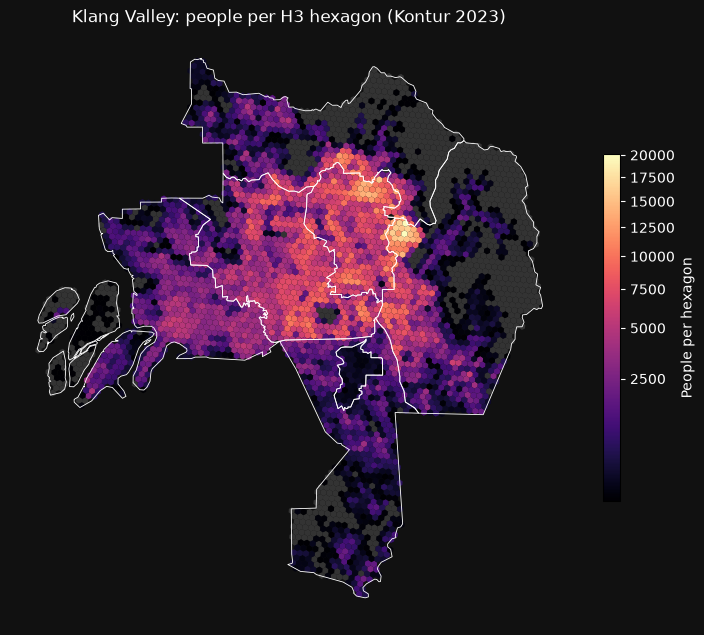

In [11]:
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from shapely.geometry import Polygon

# H3 gives the corners as (lat, lon); shapely wants (lon, lat)
shapes = grid["h3"].map(lambda c: Polygon([(lon, lat) for lat, lon in h3.cell_to_boundary(c)]))
preview = gpd.GeoDataFrame(grid, geometry=list(shapes), crs=4326)

fig, ax = plt.subplots(figsize=(9, 9), facecolor="#111111")
ax.set_facecolor("#111111")
preview[preview["population"] == 0].plot(ax=ax, color="#333333")
preview[preview["population"] > 0].plot(ax=ax, column="population", cmap="magma", norm=PowerNorm(0.5), legend=True, legend_kwds={"shrink": 0.5, "label": "People per hexagon"})
districts.boundary.plot(ax=ax, color="white", linewidth=0.6)
ax.set_axis_off()
ax.set_title("Klang Valley: people per H3 hexagon (Kontur 2023)", color="white")
fig.axes[-1].tick_params(colors="white"); fig.axes[-1].yaxis.label.set_color("white")
plt.savefig(OUTPUT / "stage1_preview.png", dpi=110, bbox_inches="tight")
plt.show()

___
**END**